# Avance del proyecto GLPI — Ciencia de Datos y Big Data
**Casos de mesa de servicio TI · 2024–2026**  
**Estado:** análisis exploratorio y modelos iniciales realizados; procesamiento PySpark pendiente de ejecución.

Cuaderno reproducible a partir de `analisis.py`, `resultados.json`, `pipeline_spark_pendiente.py` y los tres CSV. La fecha **Tiempo de solución** corresponde al límite del ANS; hay incumplimiento si `Fecha de solución > Tiempo de solución`.

**Uso:** colocar los tres CSV en la misma carpeta que este cuaderno. Ejecutar las celdas en orden. No publicar los CSV ni títulos de casos sin autorización institucional.

## 1. Bibliotecas y ubicación de archivos

In [1]:
# Instalar previamente: pip install pandas numpy matplotlib scikit-learn pyarrow
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, precision_score, recall_score, f1_score, confusion_matrix
BASE = Path.cwd()
FILES = {'2024': BASE/'GLPI-2024.csv', '2025': BASE/'GLPI-2025.csv', '2026': BASE/'GLPI-2026.csv'}
missing = [str(f) for f in FILES.values() if not f.exists()]
if missing: raise FileNotFoundError('Faltan archivos CSV en la carpeta del notebook: '+', '.join(missing))
print('Archivos encontrados:',*[f'{y}: {f.name}' for y,f in FILES.items()],sep='\n')

Archivos encontrados:
2024: GLPI-2024.csv
2025: GLPI-2025.csv
2026: GLPI-2026.csv


## 2. Ingesta y control de calidad

In [2]:
frames=[]; sizes={}
for year, file in FILES.items():
    part=pd.read_csv(file, sep=';', dtype=str, encoding='utf-8')
    part.columns=part.columns.str.strip()
    part['exportacion']=year
    frames.append(part)
    sizes[file.name]=file.stat().st_size
raw=pd.concat(frames, ignore_index=True)
raw['ID']=raw['ID'].str.replace(' ','',regex=False)
for col in ['Fecha de Apertura','Fecha de solución','Tiempo de solución']:
    raw[col+'_dt']=pd.to_datetime(raw[col], dayfirst=True, errors='coerce')
raw['duracion_horas']=(raw['Fecha de solución_dt']-raw['Fecha de Apertura_dt']).dt.total_seconds()/3600
raw['incumple_ans']=np.where(raw['Fecha de solución_dt'].notna() & raw['Tiempo de solución_dt'].notna(), (raw['Fecha de solución_dt']>raw['Tiempo de solución_dt']).astype(int), np.nan)
raw['anio_apertura']=raw['Fecha de Apertura_dt'].dt.year
raw['mes_apertura']=raw['Fecha de Apertura_dt'].dt.to_period('M').astype(str)
quality=pd.DataFrame({'nulos':raw.isna().sum(),'porcentaje_nulos':(raw.isna().mean()*100).round(2)})
print('Filas:',len(raw),'IDs duplicados:',raw.ID.duplicated().sum(),'duraciones negativas:',int((raw.duracion_horas<0).sum()))
print('Tamaño CSV total (MB):',round(sum(sizes.values())/1e6,2))
display(quality)

Filas: 200375 IDs duplicados: 0 duraciones negativas: 0
Tamaño CSV total (MB): 27.5


,nulos,porcentaje_nulos
ID,0,0.0
Título,0,0.0
Departamento,0,0.0
Estado,0,0.0
Fecha de Apertura,0,0.0
Tipo,0,0.0
Fecha de solución,0,0.0
Tiempo de solución,0,0.0
exportacion,0,0.0
Fecha de Apertura_dt,0,0.0


## 3. Análisis exploratorio (EDA)

In [3]:
print('Por exportación:');display(raw.groupby('exportacion').size().rename('casos').to_frame())
print('Por tipo:');display(raw['Tipo'].value_counts().rename_axis('tipo').to_frame('casos'))
print('Tasa de incumplimiento:',f'{raw.incumple_ans.mean()*100:.2f}%')
print('Mediana de duración (horas):',raw.loc[raw.duracion_horas>=0,'duracion_horas'].median())
print('Años reales de apertura:');display(raw.anio_apertura.value_counts().sort_index().to_frame('casos'))

Por exportación:


,casos
exportacion,
2024,58647
2025,83709
2026,58019


Por tipo:


,casos
tipo,
Requerimiento,188855
Incidencia,11520


Tasa de incumplimiento: 20.19%
Mediana de duración (horas): 33.5
Años reales de apertura:


,casos
anio_apertura,
2018,1
2019,4
2020,38
2021,26
2022,91
2023,1421
2024,58330
2025,83871
2026,56593


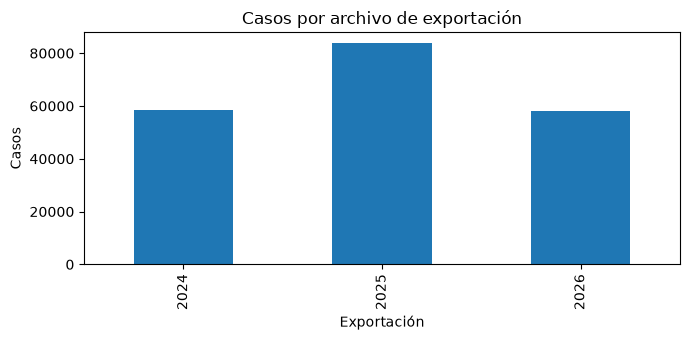

In [4]:
fig,ax=plt.subplots(figsize=(7,3.5))
raw.groupby('exportacion').size().plot.bar(ax=ax)
ax.set(title='Casos por archivo de exportación',xlabel='Exportación',ylabel='Casos')
plt.tight_layout();plt.show()

**Interpretación:** las exportaciones de 2024, 2025 y 2026 no son equivalentes a los años efectivos de apertura. El modelo se separa por fecha real de apertura.

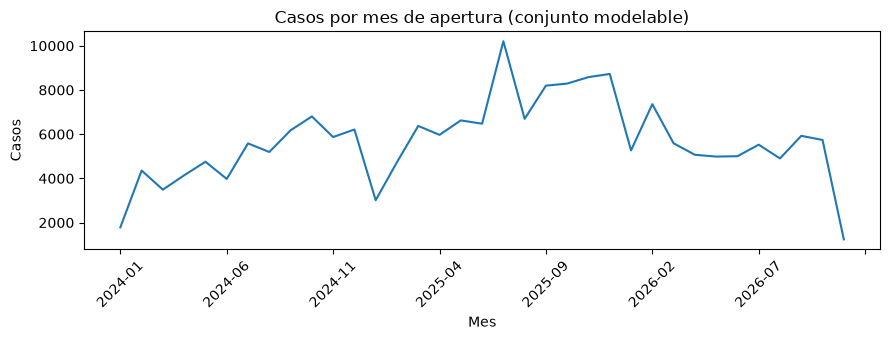

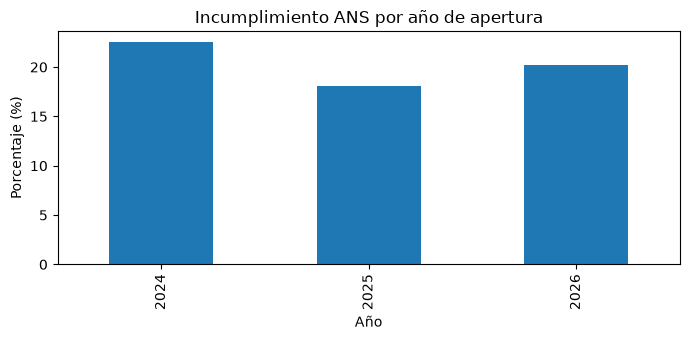

In [5]:
valid=raw.loc[raw.duracion_horas.ge(0) & raw.duracion_horas.notna() & raw.incumple_ans.notna() & raw.anio_apertura.between(2024,2026)].copy()
valid['hora']=valid['Fecha de Apertura_dt'].dt.hour
valid['dia_semana']=valid['Fecha de Apertura_dt'].dt.dayofweek
valid['mes']=valid['Fecha de Apertura_dt'].dt.month
valid=valid.sort_values('Fecha de Apertura_dt')
fig,ax=plt.subplots(figsize=(9,3.5))
valid.groupby('mes_apertura').size().plot(ax=ax)
ax.set(title='Casos por mes de apertura (conjunto modelable)',xlabel='Mes',ylabel='Casos')
plt.xticks(rotation=45);plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(7,3.5))
(valid.groupby('anio_apertura').incumple_ans.mean()*100).plot.bar(ax=ax)
ax.set(title='Incumplimiento ANS por año de apertura',xlabel='Año',ylabel='Porcentaje (%)')
plt.tight_layout();plt.show()

**Interpretación:** las tasas son descriptivas de casos cerrados exportados. No deben extrapolarse automáticamente a casos abiertos. El plazo ANS se compara con la fecha real de solución, sujeto a reglas y excepciones institucionales.

## 4. Preparación y partición temporal

In [6]:
features=['Departamento','Tipo','hora','dia_semana','mes']
tr=valid[valid.anio_apertura==2024]
va=valid[valid.anio_apertura==2025]
te=valid[valid.anio_apertura==2026]
print('Entrenamiento 2024:',len(tr),'Validación 2025:',len(va),'Prueba 2026:',len(te))
pre=ColumnTransformer([('categoricas',OneHotEncoder(handle_unknown='ignore'),['Departamento','Tipo']),('numericas','passthrough',['hora','dia_semana','mes'])])

Entrenamiento 2024: 58330 Validación 2025: 83871 Prueba 2026: 56593


**Prevención de fuga:** `Fecha de solución`, `Estado` final y el plazo ANS no se usan como predictores. La fecha límite solo podría incorporarse si se comprueba que se conoce al abrir el caso. Se reportan horas calendario; las horas hábiles requieren calendario institucional.

## 5. Modelos de regresión — horas de resolución

In [7]:
regression={}
for name,est in [('Mediana',DummyRegressor(strategy='median')),('Ridge',Ridge(alpha=20)),('Random Forest',RandomForestRegressor(n_estimators=45,max_depth=13,min_samples_leaf=10,n_jobs=-1,random_state=42))]:
    pipe=Pipeline([('prep',pre),('model',est)])
    pipe.fit(tr[features],tr.duracion_horas)
    pred=pipe.predict(te[features])
    regression[name]={'MAE':mean_absolute_error(te.duracion_horas,pred),'RMSE':np.sqrt(mean_squared_error(te.duracion_horas,pred)),'R2':r2_score(te.duracion_horas,pred)}
display(pd.DataFrame(regression).T.round(3))

,MAE,RMSE,R2
Mediana,113.261,320.518,-0.068
Ridge,167.978,314.833,-0.030
Random Forest,172.399,327.626,-0.116


**Lectura crítica:** en el análisis inicial, los modelos de regresión no mejoraron el MAE de la línea base. Se mantienen estos resultados sin atribuirles una mejora inexistente. El conjunto 2025 queda reservado para ajustes futuros; esta primera comparación reproduce el código original, entrenado en 2024 y evaluado en 2026.

## 6. Clasificación — incumplimiento de ANS

In [8]:
classification={}
for name,est in [('Mayoritaria',DummyClassifier(strategy='most_frequent')),('Logística',LogisticRegression(max_iter=500,class_weight='balanced')),('Random Forest',RandomForestClassifier(n_estimators=45,max_depth=13,min_samples_leaf=12,class_weight='balanced_subsample',n_jobs=-1,random_state=42))]:
    pipe=Pipeline([('prep',pre),('model',est)])
    pipe.fit(tr[features],tr.incumple_ans.astype(int))
    pred=pipe.predict(te[features])
    classification[name]={'precision':precision_score(te.incumple_ans,pred,zero_division=0),'recall':recall_score(te.incumple_ans,pred,zero_division=0),'F1':f1_score(te.incumple_ans,pred,zero_division=0)}
display(pd.DataFrame(classification).T.round(3))

,precision,recall,F1
Mayoritaria,0.000,0.000,0.000
Logística,0.234,0.523,0.323
Random Forest,0.242,0.649,0.353


## 7. Exportación de resultados

In [9]:
out=BASE/'resultados_notebook';out.mkdir(exist_ok=True)
valid[['ID','Departamento','Tipo','Fecha de Apertura_dt','duracion_horas','incumple_ans','anio_apertura']].to_csv(out/'casos_analiticos.csv',index=False)
summary={'filas':len(raw),'filas_modelo':len(valid),'duplicados':int(raw.ID.duplicated().sum()),'tasa_incumplimiento':float(raw.incumple_ans.mean()),'particiones':{'2024':len(tr),'2025':len(va),'2026':len(te)},'regresion':regression,'clasificacion':classification}
(out/'metricas.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('Resultados en',out)

Resultados en c:\Users\ETITC\OneDrive - Escuela Tecnologica Instituto Tecnico Central\7 SEMESTRE\CIENCIA DE DATOS\proyecto final\proyecto_GLPI\resultados_notebook


## 8. Componente Big Data — PySpark y Parquet (pendiente de verificación)
Esta sección es **ejecutable**, pero **no se ha ejecutado ni validado aquí**. Requiere Java y `pyspark`. Ejecutarla por separado y adjuntar capturas/logs para demostrar el requisito de Big Data. No se presentan resultados ficticios.

In [10]:
# pip install pyspark pyarrow
# Descomentar y ejecutar después de instalar Java y PySpark:
# from pyspark.sql import SparkSession, functions as F
# spark=SparkSession.builder.master('local[*]').appName('GLPI-ANS').getOrCreate()
# files=[str(f) for f in FILES.values()]
# sdf=spark.read.option('header',True).option('sep',';').option('encoding','UTF-8').csv(files)
# sdf.write.mode('overwrite').parquet(str(BASE/'data'/'bronze'))
# def parse_date(column):
#     return F.coalesce(F.to_timestamp(F.col(column),'d/M/yyyy H:mm'), F.to_timestamp(F.col(column),'dd/MM/yyyy HH:mm'), F.to_timestamp(F.col(column),'yyyy-MM-dd HH:mm:ss'))
# d=sdf.withColumn('id_limpio',F.regexp_replace(F.col('ID'),' ',''))
# for source,target in [('Fecha de Apertura','apertura'),('Fecha de solución','solucion'),('Tiempo de solución','limite_ans')]:
#     d=d.withColumn(target,parse_date(source))
# d=d.withColumn('duracion_horas',(F.unix_timestamp('solucion')-F.unix_timestamp('apertura'))/3600)
# d=d.withColumn('incumple_ans',F.when(F.col('solucion').isNull()|F.col('limite_ans').isNull(),F.lit(None)).when(F.col('solucion')>F.col('limite_ans'),1).otherwise(0))
# d=d.withColumn('anio_apertura',F.year('apertura')).dropDuplicates(['id_limpio'])
# d.write.mode('overwrite').partitionBy('anio_apertura').parquet(str(BASE/'data'/'silver'))
# gold=d.groupBy('anio_apertura','Tipo','Departamento').agg(F.count('*').alias('casos'),F.avg('incumple_ans').alias('tasa_incumplimiento'),F.expr('percentile_approx(duracion_horas,0.5)').alias('mediana_horas'))
# gold.write.mode('overwrite').parquet(str(BASE/'data'/'gold'))
# print('Casos:',d.count(),'Grupos:',gold.count())
# spark.stop()

## 9. Actividades pendientes
1. Ejecutar y documentar PySpark y Parquet; comparar tiempos, memoria y tamaño frente a Pandas/CSV.
2. Mejorar modelos utilizando validación 2025 sin tocar la prueba 2026 hasta seleccionar el modelo.
3. Confirmar reglas de ANS y evaluar horas hábiles si se dispone de calendarios.
4. Preparar dashboard Streamlit y conclusiones.
5. Publicar cuaderno y salidas en un repositorio autorizado con permiso de lectura, sin exponer datos institucionales sensibles.